# GEDI provider walkthrough

This notebook queries GEDI observations from the public GFZ `gedidb` endpoint and returns a shot-indexed Xarray dataset. It demonstrates scalar (`agbd`) and profile (`rh`) variables and prepares the native result for the tomo-canopy data interface.

Install the optional dependencies before running it:

```bash
python -m pip install -e '.[gedi,examples]'
```

In [5]:
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

from tomo_canopy.providers import GEDIProvider
from tomo_canopy.types import DataLayer, GeometryType, Modality

## Define a region and query

The example bounding box is a small area in southwestern Ghana. Adjust `BBOX`, dates, and variables for your site. Query geometry must describe WGS84 longitude and latitude; `gedidb` performs the spatial selection.

In [6]:
BBOX = (-2.70, 5.10, -2.50, 5.30)  # west, south, east, north
START_TIME = "2019-01-01"
END_TIME = "2024-07-25"
VARIABLES = ["agbd", "rh"]

region = gpd.GeoDataFrame(
    {"name": ["example_roi"]},
    geometry=[box(*BBOX)],
    crs="EPSG:4326",
)
region

,name,geometry
0,example_roi,"POLYGON ((-2.5 5.1, -2.5 5.3, -2.7 5.3, -2.7 5..."


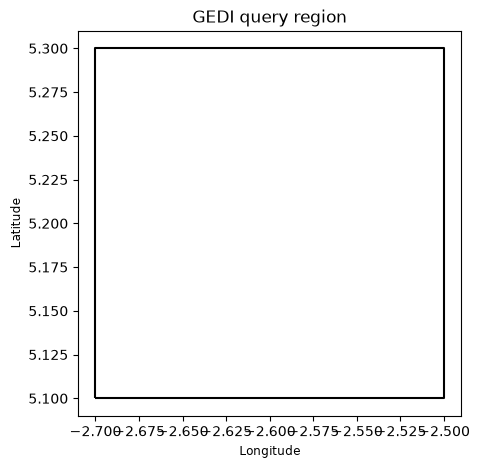

In [7]:
ax = region.boundary.plot(figsize=(6, 5), color="black")
ax.set(xlabel="Longitude", ylabel="Latitude", title="GEDI query region")
plt.show()

## Query the public GFZ store

`GEDIProvider` defaults to the public S3-compatible endpoint shown below. The first query may take some time depending on region size and network conditions.

In [8]:
provider = GEDIProvider(
    storage_type="s3",
    s3_bucket="dog-ext.gedidb.gedi-l2-l4-v002.0",
    url="https://s3.gfz-potsdam.de",
)

gedi = provider.get_data(
    variables=VARIABLES,
    geometry=region,
    query_type="bounding_box",
    start_time=START_TIME,
    end_time=END_TIME,
)
gedi

<xarray.Dataset> Size: 10MB
Dimensions:         (shot_number: 21234, profile_points: 101)
Coordinates:
  * shot_number     (shot_number) uint64 170kB 308180000300297325 ... 3078000...
    latitude        (shot_number) float64 170kB 5.107 5.106 5.1 ... 5.11 5.109
    longitude       (shot_number) float64 170kB -2.679 -2.679 ... -2.514 -2.514
    time            (shot_number) datetime64[ns] 170kB 2024-05-22 ... 2019-06-29
    x               (shot_number) float64 170kB -2.679 -2.679 ... -2.514 -2.514
    y               (shot_number) float64 170kB 5.107 5.106 5.1 ... 5.11 5.109
  * profile_points  (profile_points) int16 202B 0 1 2 3 4 5 ... 96 97 98 99 100
Data variables:
    agbd            (shot_number) float32 85kB 51.77 28.68 40.94 ... 126.2 73.8
    rh              (shot_number, profile_points) float32 9MB -3.31 ... 15.17
Attributes:
    source:               gedidb
    modality:             gedi
    geometry_type:        point_cloud
    crs:                  EPSG:4326
    storage_type:         s3
    query_type:           bounding_box
    requested_variables:  ['agbd', 'rh']
    s3_bucket:            dog-ext.gedidb.gedi-l2-l4-v002.0
    query_start_time:     2019-01-01
    query_end_time:       2024-07-25

## Inspect the normalized result

The native `longitude` and `latitude` coordinates are preserved. The provider also supplies `x` and `y` aliases and records the WGS84 CRS and query provenance. If no matching shots exist, the result is a valid empty dataset.

In [9]:
shot_count = gedi.sizes.get("shot_number", 0)
print(f"Returned shots: {shot_count:,}")
print("CRS:", gedi.attrs["crs"])
print("Variables:", list(gedi.data_vars))
print("Coordinates:", list(gedi.coords))
if shot_count == 0:
    print("No shots matched this region, date range, and variable selection.")

Returned shots: 21,234
CRS: EPSG:4326
Variables: ['agbd', 'rh']
Coordinates: ['shot_number', 'profile_points', 'latitude', 'longitude', 'time', 'x', 'y']


## Plot shot locations and biomass

The plot is skipped safely if the query returned no observations.

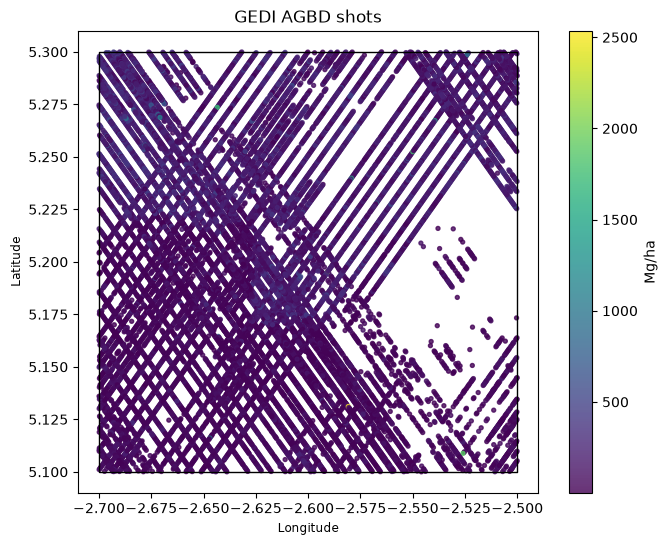

In [10]:
if shot_count:
    fig, ax = plt.subplots(figsize=(8, 6))
    region.boundary.plot(ax=ax, color="black", linewidth=1)
    shots = ax.scatter(
        gedi.longitude,
        gedi.latitude,
        c=gedi.agbd,
        s=8,
        cmap="viridis",
        alpha=0.8,
    )
    ax.set(xlabel="Longitude", ylabel="Latitude", title="GEDI AGBD shots")
    fig.colorbar(shots, ax=ax, label=gedi.agbd.attrs.get("units", "AGBD"))
    plt.show()

## Plot one RH profile

`gedidb` retains profile variables as two-dimensional arrays indexed by shot and a variable-specific profile coordinate. The code discovers that coordinate rather than assuming its exact name.

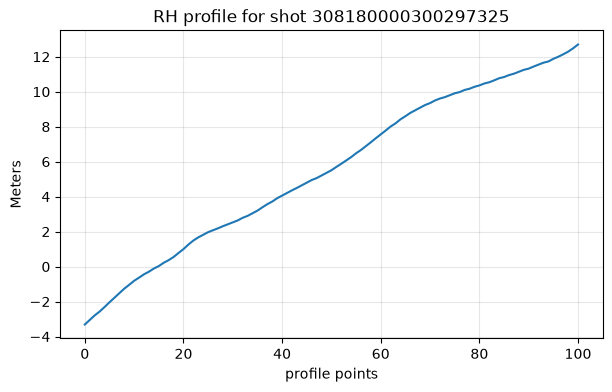

In [11]:
if shot_count and "rh" in gedi:
    profile_dimensions = [
        dimension for dimension in gedi.rh.dims if dimension != "shot_number"
    ]
    if profile_dimensions:
        profile_dimension = profile_dimensions[0]
        profile = gedi.rh.isel(shot_number=0)
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.plot(profile[profile_dimension], profile)
        ax.set(
            xlabel=profile_dimension.replace("_", " "),
            ylabel=gedi.rh.attrs.get("units", "RH"),
            title=f"RH profile for shot {gedi.shot_number.data[0]}",
        )
        ax.grid(alpha=0.3)
        plt.show()

## Create a native GEDI data layer

A `DataLayer` records modality, geometry, and CRS without forcing the shot data onto a cube prematurely. A future GEDI processor and cube generator will reproject and aggregate these footprints onto a shared `GridSpec` before adding them to a `DataCube`.

In [12]:
gedi_layer = DataLayer(
    name="gedi_shots",
    data=gedi,
    modality=Modality.GEDI,
    geometry=GeometryType.POINT_CLOUD,
)
print("Layer:", gedi_layer.name)
print("Modality:", gedi_layer.modality)
print("Geometry:", gedi_layer.geometry)
print("CRS:", gedi_layer.crs)

Layer: gedi_shots
Modality: gedi
Geometry: point_cloud
CRS: EPSG:4326


## Optional quality filters

Filters supported by `gedidb` can be passed either as a mapping or as keyword arguments. Use variable names and expressions supported by the selected GEDI products.

```python
filtered = provider.get_data(
    variables=VARIABLES,
    geometry=region,
    start_time=START_TIME,
    end_time=END_TIME,
    quality_filters={"l4_quality_flag": "= 1"},
)
```